# Práctica 2.2 · Árbol de decisión: ¿qué hogares priorizar para un subsidio?

Este cuaderno acompaña la clase «Árbol de decisión» y sigue su mismo recorrido:

1. Explorar los datos · 2. Separar **entrenamiento y validación** · 3. Un árbol pequeño: **preguntas en cadena** · 4. Cómo elige cada corte: **impureza de Gini** · 5. Leer cada rama como una **regla** · 6. **Profundidad y sobreajuste** · 7. Hiperparámetros con validación cruzada · 8. **Métricas** contra la línea base y la regresión logística · 9. Curva ROC y umbral · 10. **Importancia** de las variables

**Datos.** `datos/2-2-hogares-subsidio.xlsx` tiene 1.200 hogares **simulados con fines didácticos**, al estilo de las encuestas de calidad de vida y del SISBÉN: municipio, zona, tamaño del hogar, educación de quien lo encabeza, ocupados, ingreso por persona, hacinamiento, acueducto, piso de tierra, internet y régimen de salud. La variable objetivo, **pobre (Sí/No)**, se generó con umbrales e interacciones conocidos (por ejemplo, el ingreso bajo pesa más cuando la educación de quien encabeza el hogar es baja), justo el tipo de estructura que un árbol puede descubrir y una recta no. La misma base se usa en la práctica de random forest.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. Cargar y explorar los datos

In [3]:
hog = pd.read_excel(DATOS / '2-2-hogares-subsidio.xlsx', sheet_name='hogares')
diccionario = pd.read_excel(DATOS / '2-2-hogares-subsidio.xlsx', sheet_name='diccionario')
hog['es_pobre'] = (hog['pobre'] == 'Sí').astype(int)
print(hog.shape)
hog.head()

(1200, 18)


,id_hogar,tipo_municipio,zona,personas,menores_5,adultos_mayores,educacion_jefe,jefe_mujer,ocupados,ingreso_pc,cuartos,hacinamiento,acueducto,piso_tierra,internet,regimen_salud,pobre,es_pobre
0,1,Rural disperso,Rural,7,1,1,7,No,3,525000,3,2.330,No,No,No,Contributivo,Sí,1
1,2,Intermedio,Urbana,6,2,0,15,No,1,964000,4,1.500,Sí,No,Sí,Contributivo,No,0
2,3,Capital,Urbana,3,0,0,9,Sí,1,698000,2,1.500,Sí,No,Sí,Contributivo,No,0
3,4,Intermedio,Rural,3,0,0,3,Sí,1,213000,3,1.000,Sí,No,No,Subsidiado,Sí,1
4,5,Capital,Urbana,4,0,0,7,Sí,1,374000,1,4.000,Sí,Sí,No,Subsidiado,Sí,1


In [4]:
diccionario

,variable,descripcion,tipo,unidad o valores
0,id_hogar,Identificador del hogar,Entero,—
1,tipo_municipio,Tipo de municipio donde vive,Categórica nominal,Capital / Intermedio / Rural disperso
2,zona,Zona de la vivienda,Categórica (binaria),Urbana / Rural
3,personas,Personas en el hogar,Numérica,personas
4,menores_5,Niñas y niños menores de 5 años,Numérica,personas
5,adultos_mayores,Personas de 65 años o más,Numérica,personas
6,educacion_jefe,Años de educación de quien encabeza el hogar,Numérica,años
7,jefe_mujer,El hogar lo encabeza una mujer,Categórica (binaria),Sí / No
8,ocupados,Personas del hogar con trabajo,Numérica,personas
9,ingreso_pc,Ingreso mensual del hogar por persona,Numérica,pesos


In [5]:
print(f"Hogares pobres: {hog['es_pobre'].sum()} de {len(hog)} ({hog['es_pobre'].mean():.1%})")
hog.groupby('pobre')[['ingreso_pc', 'hacinamiento', 'educacion_jefe', 'personas', 'menores_5']].median()

Hogares pobres: 394 de 1200 (32.8%)


,ingreso_pc,hacinamiento,educacion_jefe,personas,menores_5
pobre,,,,,
No,"848,500.000",1.500,10.000,3.000,0.000
Sí,"222,000.000",1.670,6.000,4.000,0.000


Hay **394 hogares pobres de 1.200 (32,8 %)**. La diferencia más grande está en el **ingreso por persona**: la mediana es de 222.000 pesos en los pobres y de 848.500 en los demás. También pesan la **educación de quien encabeza el hogar** (6 años frente a 10) y el tamaño del hogar (4 personas frente a 3). El hacinamiento casi no cambia en la mediana (1,67 frente a 1,50 personas por cuarto).

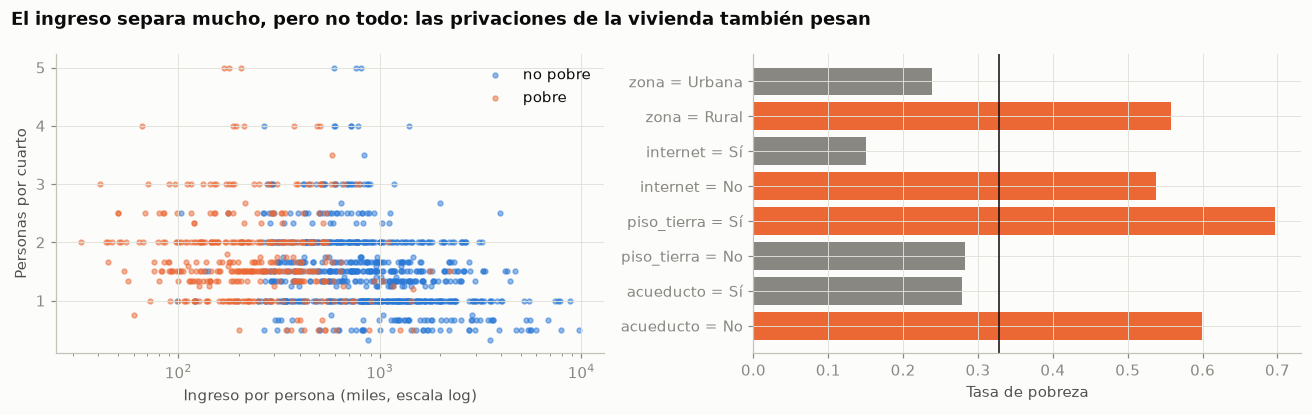

acueducto = No     0.599
acueducto = Sí     0.278
piso_tierra = No   0.283
piso_tierra = Sí   0.697
internet = No      0.537
internet = Sí      0.150
zona = Rural       0.558
zona = Urbana      0.239
dtype: float64

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for v, color, lab in [(0, AZUL, 'no pobre'), (1, NARANJA, 'pobre')]:
    d = hog[hog['es_pobre'] == v]
    axs[0].scatter(d['ingreso_pc'] / 1e3, d['hacinamiento'], s=10, alpha=.5, color=color, label=lab)
axs[0].set_xscale('log'); axs[0].set_xlabel('Ingreso por persona (miles, escala log)'); axs[0].set_ylabel('Personas por cuarto'); axs[0].legend()
tasas = pd.Series({f'{c} = {v}': hog.loc[hog[c] == v, 'es_pobre'].mean() for c in ['acueducto', 'piso_tierra', 'internet', 'zona']
                   for v in sorted(hog[c].unique())})
axs[1].barh(tasas.index, tasas.values, color=[NARANJA if v > hog['es_pobre'].mean() else GRIS for v in tasas.values])
axs[1].axvline(hog['es_pobre'].mean(), color=TINTA, lw=1); axs[1].set_xlabel('Tasa de pobreza')
plt.suptitle('El ingreso separa mucho, pero no todo: las privaciones de la vivienda también pesan', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()
tasas.round(3)

Las privaciones de la vivienda marcan diferencias grandes:

- **Sin acueducto:** 59,9 % de pobreza, frente a 27,8 % con acueducto.
- **Piso de tierra:** 69,7 %, frente a 28,3 %.
- **Sin internet:** 53,7 %, frente a 15,0 %.
- **Zona rural:** 55,8 %, frente a 23,9 % en la urbana.

En la nube de la izquierda, los hogares pobres se concentran en los ingresos bajos, pero se mezclan con los no pobres en la franja media. Ahí harán falta otras preguntas además del ingreso.

## 2. Separar entrenamiento y validación

El árbol **aprende** con el 75 % de los hogares y se **evalúa** con el 25 % que no vio. La partición es **estratificada**: los dos grupos conservan la proporción de hogares pobres. Las variables de texto se convierten en columnas de 0 y 1.

In [7]:
def preparar(d):
    X = d[['personas', 'menores_5', 'adultos_mayores', 'educacion_jefe', 'ocupados', 'ingreso_pc', 'cuartos', 'hacinamiento']].copy()
    for c in ['jefe_mujer', 'acueducto', 'piso_tierra', 'internet']:
        X[c] = (d[c] == 'Sí').astype(int)
    X['rural'] = (d['zona'] == 'Rural').astype(int)
    return X.join(pd.get_dummies(d[['tipo_municipio', 'regimen_salud']], dtype=int)).astype(float)
X, y = preparar(hog), hog['es_pobre']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEMILLA, stratify=y)
print(f'Entrenamiento: {len(Xtr)} hogares ({ytr.mean():.1%} pobres) · Prueba: {len(Xte)} ({yte.mean():.1%} pobres)')
print(X.shape[1], 'variables:', ', '.join(X.columns))

Entrenamiento: 900 hogares (32.9% pobres) · Prueba: 300 (32.7% pobres)
19 variables: personas, menores_5, adultos_mayores, educacion_jefe, ocupados, ingreso_pc, cuartos, hacinamiento, jefe_mujer, acueducto, piso_tierra, internet, rural, tipo_municipio_Capital, tipo_municipio_Intermedio, tipo_municipio_Rural disperso, regimen_salud_Contributivo, regimen_salud_Ninguno, regimen_salud_Subsidiado


Quedan **900 hogares para entrenar y 300 para validar**, con casi la misma proporción de pobres (32,9 % y 32,7 %). Las 19 variables incluyen las numéricas, las de sí o no convertidas en 0 y 1, y una columna por categoría del tipo de municipio y del régimen de salud.

## 3. Un árbol pequeño: preguntas en cadena

Un árbol de decisión clasifica con una serie de preguntas de sí o no. Cada pregunta divide a los hogares en dos grupos; al final, cada **hoja** predice la clase más frecuente entre los hogares de entrenamiento que llegaron a ella. Se empieza con un árbol de **profundidad 2**: dos preguntas como máximo.

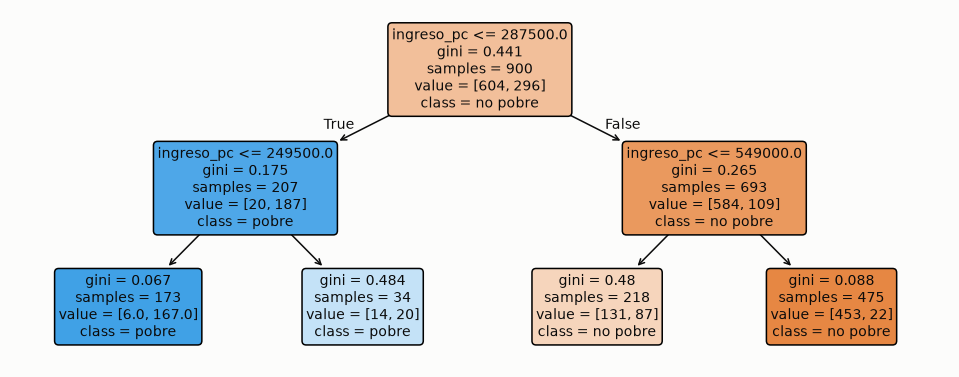

|--- ingreso_pc <= 287500.00
|   |--- ingreso_pc <= 249500.00
|   |   |--- weights: [6.00, 167.00] class: 1
|   |--- ingreso_pc >  249500.00
|   |   |--- weights: [14.00, 20.00] class: 1
|--- ingreso_pc >  287500.00
|   |--- ingreso_pc <= 549000.00
|   |   |--- weights: [131.00, 87.00] class: 0
|   |--- ingreso_pc >  549000.00
|   |   |--- weights: [453.00, 22.00] class: 0



In [8]:
arbol2 = DecisionTreeClassifier(max_depth=2, random_state=SEMILLA).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(11, 4.2))
plot_tree(arbol2, feature_names=list(X.columns), class_names=['no pobre', 'pobre'], filled=True, rounded=True, impurity=True, proportion=False, ax=ax, fontsize=9)
plt.show()
print(export_text(arbol2, feature_names=list(X.columns), show_weights=True))

Con profundidad 2, **las dos preguntas son sobre el ingreso**:

- **Hasta 249.500 pesos:** 167 de 173 hogares son pobres (96,5 %).
- **Entre 249.500 y 287.500:** 20 de 34 (59 %).
- **Entre 287.500 y 549.000:** el grupo queda **mezclado**, con 87 pobres de 218 (40 %). El árbol predice «no pobre» porque es la mayoría, y se equivoca con muchos.
- **Por encima de 549.000:** solo 22 de 475 (4,6 %).

Ese grupo intermedio necesita otra pregunta. Por eso un árbol tan pequeño se queda corto.

## 4. Cómo elige cada corte: la impureza de Gini

En cada nodo, el algoritmo **CART** (*Classification And Regression Trees*) prueba todas las variables y todos los umbrales posibles, y se queda con el corte que deja los grupos **más puros**. La pureza se mide con el **índice de Gini**:

$$\text{Gini} = 1 - p_{\text{pobre}}^2 - p_{\text{no pobre}}^2$$

Vale 0 si el grupo es todo de una clase y 0,5 si está mitad y mitad. Un corte se califica con el **Gini ponderado** de los dos grupos que crea (cada uno pesa según su tamaño). Se gana tanto como baja el Gini.

Gini del nodo raíz: 0.4414 (scikit-learn: 0.4414)
Primer corte: ingreso_pc ≤ 287,500
  izquierda: 207 hogares, Gini 0.1746 · derecha: 693 hogares, Gini 0.2651
  Gini ponderado: 0.2443 → baja 0.1972


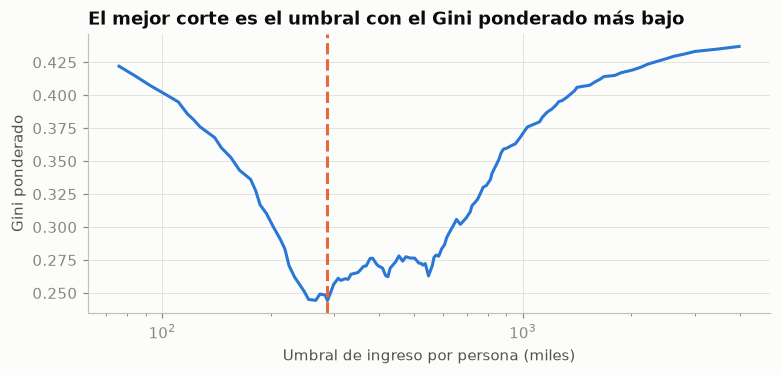

Mínimo del barrido: ingreso ≤ 287,543 con Gini ponderado 0.2443


In [9]:
gini = lambda yy: 1 - (yy.mean() ** 2 + (1 - yy.mean()) ** 2) if len(yy) else 0
var = X.columns[arbol2.tree_.feature[0]]; umbral = arbol2.tree_.threshold[0]
izq, der = ytr[Xtr[var] <= umbral], ytr[Xtr[var] > umbral]
pond = (len(izq) * gini(izq) + len(der) * gini(der)) / len(ytr)
print(f'Gini del nodo raíz: {gini(ytr):.4f} (scikit-learn: {arbol2.tree_.impurity[0]:.4f})')
print(f'Primer corte: {var} ≤ {umbral:,.0f}')
print(f'  izquierda: {len(izq)} hogares, Gini {gini(izq):.4f} · derecha: {len(der)} hogares, Gini {gini(der):.4f}')
print(f'  Gini ponderado: {pond:.4f} → baja {gini(ytr) - pond:.4f}')
# barrido de umbrales para el ingreso: la curva del Gini ponderado y su mínimo
us = np.quantile(Xtr['ingreso_pc'], np.linspace(.02, .98, 120))
gp = [(lambda a, b: (len(a) * gini(a) + len(b) * gini(b)) / len(ytr))(ytr[Xtr['ingreso_pc'] <= u], ytr[Xtr['ingreso_pc'] > u]) for u in us]
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(us / 1e3, gp, color=AZUL); ax.axvline(us[np.argmin(gp)] / 1e3, color=NARANJA, ls='--')
ax.set_xscale('log'); ax.set_xlabel('Umbral de ingreso por persona (miles)'); ax.set_ylabel('Gini ponderado')
ax.set_title('El mejor corte es el umbral con el Gini ponderado más bajo'); plt.show()
print(f'Mínimo del barrido: ingreso ≤ {us[np.argmin(gp)]:,.0f} con Gini ponderado {min(gp):.4f}')

El cálculo a mano coincide con `scikit-learn`: el **Gini del nodo raíz es 0,4414**, porque con un 33 % de pobres el grupo está bastante mezclado. El primer corte, **ingreso ≤ 287.500**, deja dos grupos más puros:

- a la izquierda, 207 hogares con Gini 0,1746;
- a la derecha, 693 con Gini 0,2651.

El Gini ponderado baja a **0,2443**, una ganancia de 0,1972. El barrido de umbrales muestra la curva completa: su mínimo cae en 287.543, el mismo corte que eligió el algoritmo. Es la misma lógica de mínimos cuadrados en la regresión lineal: **probar y quedarse con el que menos se equivoca**.

## 5. Leer cada rama como una regla

Lo que más se valora de un árbol es que **se puede leer**. Cada camino desde la raíz hasta una hoja es una regla del tipo «si… y… entonces…». Con profundidad 3 se ve así:

In [10]:
arbol3 = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA).fit(Xtr, ytr)
t = arbol3.tree_
def reglas(nodo=0, cond=()):
    if t.children_left[nodo] == -1:
        n = t.n_node_samples[nodo]; p = t.value[nodo][0][1] / t.value[nodo][0].sum()
        return [{'regla': ' y '.join(cond) or '(todos)', 'hogares': n, '% pobres': p, 'predice': 'pobre' if p >= .5 else 'no pobre'}]
    v, u = X.columns[t.feature[nodo]], t.threshold[nodo]
    fmt = (lambda u: f'{u:,.0f}') if v == 'ingreso_pc' else (lambda u: f'{u:.2f}')
    return reglas(t.children_left[nodo], cond + (f'{v} ≤ {fmt(u)}',)) + reglas(t.children_right[nodo], cond + (f'{v} > {fmt(u)}',))
tabla_reglas = pd.DataFrame(reglas()).sort_values('% pobres', ascending=False)
with pd.option_context('display.max_colwidth', None):
    display(tabla_reglas)

,regla,hogares,% pobres,predice
0,"ingreso_pc ≤ 287,500 y ingreso_pc ≤ 249,500 y educacion_jefe ≤ 8.50",117,1.000,pobre
1,"ingreso_pc ≤ 287,500 y ingreso_pc ≤ 249,500 y educacion_jefe > 8.50",56,0.893,pobre
2,"ingreso_pc ≤ 287,500 y ingreso_pc > 249,500 y educacion_jefe ≤ 8.50",26,0.731,pobre
4,"ingreso_pc > 287,500 y ingreso_pc ≤ 549,000 y educacion_jefe ≤ 8.50",123,0.683,pobre
7,"ingreso_pc > 287,500 y ingreso_pc > 549,000 y piso_tierra > 0.50",27,0.296,no pobre
3,"ingreso_pc ≤ 287,500 y ingreso_pc > 249,500 y educacion_jefe > 8.50",8,0.125,no pobre
5,"ingreso_pc > 287,500 y ingreso_pc ≤ 549,000 y educacion_jefe > 8.50",95,0.032,no pobre
6,"ingreso_pc > 287,500 y ingreso_pc > 549,000 y piso_tierra ≤ 0.50",448,0.031,no pobre


Con profundidad 3, el árbol descubre la **interacción** con la que se simularon los datos. En la franja de ingreso entre 287.500 y 549.000 pesos:

- si quien encabeza el hogar tiene **8 años de educación o menos**, el **68,3 %** de los hogares es pobre (123 hogares);
- con **más educación**, solo el **3,2 %** (95 hogares).

El mismo ingreso significa cosas distintas según la educación. Una recta no puede expresar eso con un solo coeficiente; el árbol lo hace con dos preguntas seguidas. Otras reglas claras:

- **Ingreso hasta 249.500 y educación baja:** los 117 hogares son pobres (100 %).
- **Ingreso alto y piso de tierra:** el 29,6 % es pobre; **ingreso alto sin piso de tierra:** solo el 3,1 %.

## 6. Profundidad y sobreajuste

Si se deja crecer el árbol sin límite, termina haciendo una hoja casi para cada hogar: **memoriza** el entrenamiento y falla con datos nuevos. Eso es el **sobreajuste**. Se ve comparando la exactitud en entrenamiento y en prueba según la profundidad máxima.

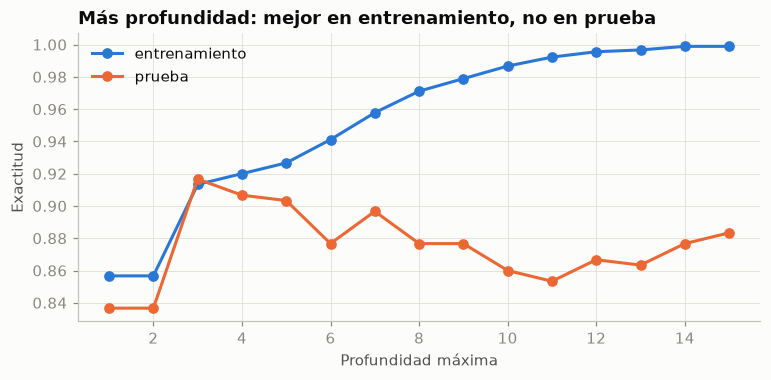

,entrenamiento,prueba,hojas
profundidad,,,
1,0.857,0.837,2
2,0.857,0.837,4
3,0.913,0.917,8
4,0.920,0.907,15
5,0.927,0.903,24
6,0.941,0.877,38
8,0.971,0.877,63
10,0.987,0.860,81
15,0.999,0.883,93


In [11]:
prof = range(1, 16)
res = pd.DataFrame([{'profundidad': d,
                     'entrenamiento': accuracy_score(ytr, (m := DecisionTreeClassifier(max_depth=d, random_state=SEMILLA).fit(Xtr, ytr)).predict(Xtr)),
                     'prueba': accuracy_score(yte, m.predict(Xte)), 'hojas': m.get_n_leaves()} for d in prof]).set_index('profundidad')
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(res.index, res['entrenamiento'], 'o-', color=AZUL, label='entrenamiento'); ax.plot(res.index, res['prueba'], 'o-', color=NARANJA, label='prueba')
ax.set_xlabel('Profundidad máxima'); ax.set_ylabel('Exactitud'); ax.legend(); ax.set_title('Más profundidad: mejor en entrenamiento, no en prueba'); plt.show()
res.loc[[1, 2, 3, 4, 5, 6, 8, 10, 15]]

Más profundidad no es mejor:

- **Entrenamiento:** la exactitud sube sin parar, de 0,857 con profundidad 1 a **0,999 con profundidad 15**. Con esa profundidad el árbol tiene 93 hojas, casi una regla para cada pocos hogares.
- **Prueba:** la exactitud es máxima con **profundidad 3 (0,917)** y luego cae hasta 0,860 con profundidad 10.

La brecha entre las dos curvas es el **sobreajuste**: el árbol memoriza el ruido del entrenamiento.

## 7. Hiperparámetros con validación cruzada

El árbol tiene varios **hiperparámetros** que limitan cuánto crece:

- `max_depth`: profundidad máxima.
- `min_samples_leaf`: mínimo de hogares en cada hoja.
- `ccp_alpha`: **poda** por costo-complejidad; corta las ramas que mejoran poco.

Se eligen con **validación cruzada** (5 pliegues) en entrenamiento, usando el AUC. La prueba no se toca.

In [12]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
rejilla = {'max_depth': [2, 3, 4, 5, 6, 8, None], 'min_samples_leaf': [1, 5, 10, 20, 40], 'ccp_alpha': [0, 0.001, 0.003, 0.01]}
busq = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA), rejilla, cv=cv, scoring='roc_auc').fit(Xtr, ytr)
arbol = busq.best_estimator_
print('Mejor combinación:', busq.best_params_, f'· AUC en validación cruzada = {busq.best_score_:.3f}')
print(f'Profundidad real: {arbol.get_depth()} · hojas: {arbol.get_n_leaves()}')

Mejor combinación: {'ccp_alpha': 0, 'max_depth': 6, 'min_samples_leaf': 10} · AUC en validación cruzada = 0.942
Profundidad real: 6 · hojas: 26


La validación cruzada eligió **profundidad máxima 6 con al menos 10 hogares por hoja**, sin poda adicional, con un AUC de validación cruzada de **0,942**. El resultado tiene 26 hojas. El mínimo de hogares por hoja limita el árbol tanto como la profundidad: impide reglas basadas en dos o tres hogares.

## 8. Métricas: contra la línea base y la regresión logística

Se comparan cuatro modelos en **prueba**: la línea base (todos «no pobre»), la regresión logística con todas las variables, el árbol de profundidad 2 y el árbol ajustado. Las métricas son las de la clase de regresión logística: exactitud, precisión, sensibilidad, F1 y AUC.

In [13]:
def metricas(yv, p, u=0.5):
    h = (p >= u).astype(int)
    return {'exactitud': accuracy_score(yv, h), 'precisión': precision_score(yv, h, zero_division=0), 'sensibilidad': recall_score(yv, h),
            'F1': f1_score(yv, h), 'AUC': roc_auc_score(yv, p) if np.std(p) > 0 else 0.5}
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Xtr, ytr)
prob = {'Línea base (nadie es pobre)': np.zeros(len(yte)), 'Regresión logística': logit.predict_proba(Xte)[:, 1],
        'Árbol de profundidad 2': arbol2.predict_proba(Xte)[:, 1], 'Árbol ajustado': arbol.predict_proba(Xte)[:, 1]}
tabla = pd.DataFrame({m: metricas(yte, p) for m, p in prob.items()}).T
tabla

,exactitud,precisión,sensibilidad,F1,AUC
Línea base (nadie es pobre),0.673,0.000,0.000,0.000,0.500
Regresión logística,0.863,0.806,0.765,0.785,0.936
Árbol de profundidad 2,0.837,0.836,0.622,0.713,0.897
Árbol ajustado,0.917,0.854,0.898,0.876,0.954


La **línea base** acierta el 67,3 % sin encontrar a ningún hogar pobre. Los demás modelos, en prueba:

| Modelo | Exactitud | Sensibilidad | AUC |
|---|---|---|---|
| Regresión logística | 0,863 | 0,765 | 0,936 |
| Árbol de profundidad 2 | 0,837 | 0,622 | 0,897 |
| **Árbol ajustado** | **0,917** | **0,898** | **0,954** |

El árbol ajustado tiene además precisión 0,854 y F1 0,876. Le gana a la logística porque los datos tienen **umbrales e interacciones** (ingreso bajo con educación baja; piso de tierra con ingreso medio), que una ecuación lineal no captura sin agregarlas a mano.

In [14]:
mc = pd.DataFrame(confusion_matrix(yte, (prob['Árbol ajustado'] >= .5).astype(int)), index=['Real: no pobre', 'Real: pobre'], columns=['Predijo: no pobre', 'Predijo: pobre'])
display(mc)
pd.DataFrame({'entrenamiento': metricas(ytr, arbol.predict_proba(Xtr)[:, 1]), 'prueba': metricas(yte, prob['Árbol ajustado'])}).T

,Predijo: no pobre,Predijo: pobre
Real: no pobre,187,15
Real: pobre,10,88


,exactitud,precisión,sensibilidad,F1,AUC
entrenamiento,0.919,0.866,0.892,0.879,0.976
prueba,0.917,0.854,0.898,0.876,0.954


De los **98 hogares pobres** de prueba, el árbol encuentra a **88 (VP)** y se le escapan **10 (FN)**. De los 202 no pobres, señala por error a 15 (FP). Entre entrenamiento y prueba casi no hay diferencia: exactitud de 0,919 frente a 0,917 y AUC de 0,976 frente a 0,954. Con los límites que eligió la validación cruzada, el árbol **no está sobreajustado**.

## 9. Curva ROC y umbral

Cada hoja entrega una **probabilidad**: la proporción de hogares pobres entre los de entrenamiento que cayeron en ella. Como un árbol tiene pocas hojas, sus probabilidades toman pocos valores y su curva ROC avanza **a saltos**.

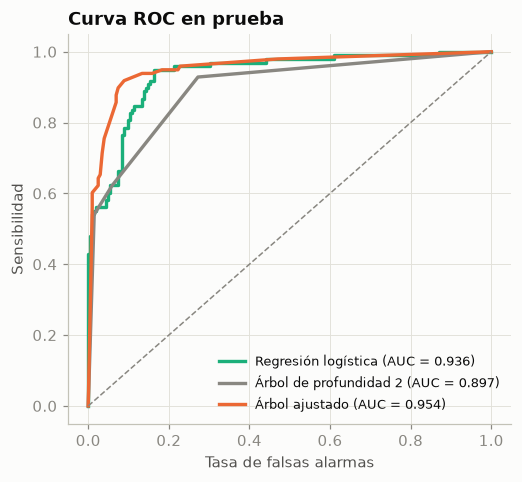

,exactitud,precisión,sensibilidad,F1
umbral,,,,
0.200,0.883,0.760,0.939,0.840
0.300,0.887,0.767,0.939,0.844
0.400,0.917,0.854,0.898,0.876
0.500,0.917,0.854,0.898,0.876
0.600,0.913,0.860,0.878,0.869


In [15]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for nombre, color in [('Regresión logística', AQUA), ('Árbol de profundidad 2', GRIS), ('Árbol ajustado', NARANJA)]:
    fpr, tpr, _ = roc_curve(yte, prob[nombre])
    ax.plot(fpr, tpr, color=color, lw=2.2, label=f'{nombre} (AUC = {roc_auc_score(yte, prob[nombre]):.3f})')
ax.plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1)
ax.set_xlabel('Tasa de falsas alarmas'); ax.set_ylabel('Sensibilidad'); ax.legend(loc='lower right', fontsize=8.5); ax.set_title('Curva ROC en prueba'); plt.show()
umbrales = pd.DataFrame({u: metricas(yte, prob['Árbol ajustado'], u) for u in [0.2, 0.3, 0.4, 0.5, 0.6]}).T.drop(columns='AUC')
umbrales.index.name = 'umbral'
umbrales

Las curvas del árbol avanzan **a saltos**, porque un árbol solo da tantas probabilidades distintas como hojas tiene. Por la misma razón, varios umbrales dan el mismo resultado: con 0,4 y con 0,5 la sensibilidad es 0,898 y la precisión 0,854. Con un umbral de **0,3** se escapan aún menos hogares pobres: la sensibilidad llega a **0,939** y se encuentran 92 de 98. A cambio, la precisión baja a 0,767, con más hogares señalados sin ser pobres. Para un subsidio, la decisión depende de qué cuesta más: **dejar fuera a un hogar pobre o incluir a uno que no lo es**.

## 10. Importancia de las variables

La **importancia** de una variable en un árbol es cuánto bajó el Gini, en total, en los cortes que la usaron (ponderado por los hogares de cada nodo). Las importancias suman 1.

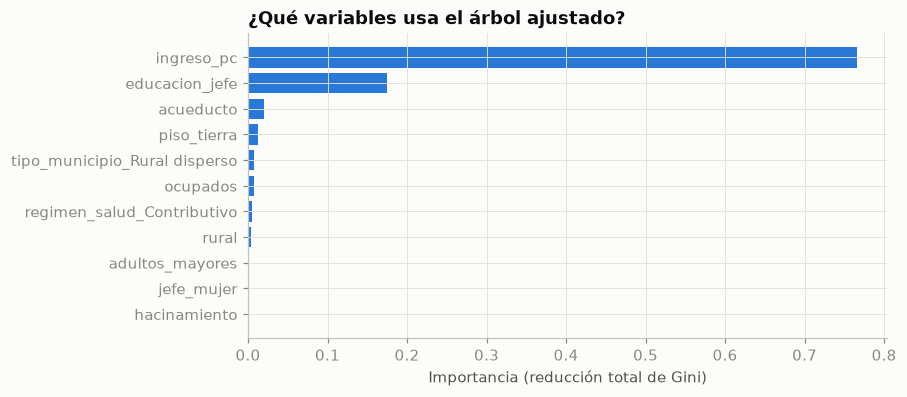

ingreso_pc                      0.766
educacion_jefe                  0.175
acueducto                       0.021
piso_tierra                     0.012
tipo_municipio_Rural disperso   0.008
ocupados                        0.007
regimen_salud_Contributivo      0.005
rural                           0.003
adultos_mayores                 0.002
jefe_mujer                      0.001
hacinamiento                    0.001
dtype: float64

In [16]:
imp = pd.Series(arbol.feature_importances_, index=X.columns).sort_values()
imp = imp[imp > 0]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(imp.index, imp.values, color=AZUL); ax.set_xlabel('Importancia (reducción total de Gini)'); ax.set_title('¿Qué variables usa el árbol ajustado?')
plt.show()
imp.sort_values(ascending=False).round(3)

El árbol ajustado se apoya casi todo en el **ingreso por persona (0,766)** y en la **educación de quien encabeza el hogar (0,175)**. Les siguen, muy atrás, el acueducto (0,021) y el piso de tierra (0,012). El hacinamiento casi no aparece (0,001): en la simulación solo importa cuando hay menores de 5 años, y esos casos son pocos. Dos advertencias:

- La importancia dice **cuánto se usó** una variable, no en qué dirección actúa ni si es una causa.
- Si dos variables cuentan casi lo mismo, el árbol suele quedarse con una y ignorar la otra.

## Conclusiones

| Pregunta | Respuesta con estos datos |
|---|---|
| ¿Qué hace un árbol? | Clasifica con preguntas de sí o no; cada hoja predice la clase más frecuente y da una probabilidad |
| ¿Cómo elige cada pregunta? | Con el corte que más baja la **impureza de Gini**: el primero, ingreso ≤ 287.500, la baja de 0,4414 a 0,2443 |
| ¿Qué ventaja tiene? | **Se lee como reglas** y descubre interacciones: con ingreso medio, la educación baja eleva la pobreza del 3,2 % al 68,3 % |
| ¿Cuál es su riesgo? | El **sobreajuste**: con profundidad 15 acierta el 99,9 % en entrenamiento y baja en prueba |
| ¿Cómo se controla? | Con hiperparámetros elegidos por validación cruzada: profundidad 6 y al menos 10 hogares por hoja |
| ¿Cuánto acierta? | En prueba: exactitud 0,917, sensibilidad 0,898 y AUC 0,954, por encima de la logística (0,936) y de la línea base |
| ¿Qué variables pesan? | Ingreso por persona y educación de quien encabeza el hogar |

Un árbol es una de las técnicas más **explicables**. Sus reglas se pueden discutir con quien toma la decisión, lo que importa en la política social. Su debilidad es la **inestabilidad**: con otros datos, el árbol puede cambiar bastante. De eso se ocupa el **random forest**, en la siguiente práctica.

## Retos

1. **Un árbol para leer en voz alta.** Entrene un árbol de profundidad 3 solo con `educacion_jefe`, `hacinamiento`, `acueducto` y `piso_tierra` (sin ingreso). ¿Qué reglas aparecen? ¿Cuánto cae el AUC?
2. **Hojas mínimas.** Dibuje la exactitud en entrenamiento y en prueba según `min_samples_leaf` (de 1 a 80), con la profundidad libre. ¿Desde qué valor desaparece el sobreajuste?
3. **Poda.** Use `cost_complexity_pruning_path` para ver cómo cambian el número de hojas y el AUC a medida que crece `ccp_alpha`.
4. **Equidad por zona.** Calcule la sensibilidad del árbol ajustado por separado para hogares rurales y urbanos. ¿A cuáles se les escapan más hogares pobres?
5. **Árbol de regresión.** Use `DecisionTreeRegressor` para predecir el `ingreso_pc` con las demás variables. ¿Qué preguntas hace el árbol? Compare su MAE con el de una regresión lineal.